# Unidad 12. Ámbito, módulos y paquetes

**Duración orientativa:** 7 horas · **Versión:** 1.0 · **UT2**

Esta unidad completa la organización del código: dónde existe cada nombre, cómo se estructura un paquete y cómo se reproducen las dependencias de un proyecto.

## 1. Ámbito de los nombres

Un nombre creado dentro de una función es local: solo se utiliza durante esa llamada. Un nombre creado en el nivel superior de un módulo es global para ese módulo. Python busca normalmente primero en el ámbito local y después en los ámbitos exteriores. Esta regla evita interferencias entre funciones.

No modifiques variables globales desde una función salvo que exista una razón muy clara. Usar global hace que una función dependa de estado oculto, sea difícil de reutilizar y complique las pruebas. Es preferible recibir el dato por parámetro y devolver el resultado. Nonlocal se reserva para funciones anidadas y no es necesario en el diseño habitual de este curso.

In [ ]:
estado = "global"

def describir_estado(estado: str) -> str:
    estado_local = estado.upper()
    return estado_local

print(describir_estado("local"))
print(estado)


## 2. Paquetes y estructura

Una estructura sencilla separa código reutilizable, pruebas y datos. Por ejemplo: modulos/confort.py para funciones; pruebas/test_confort.py para pruebas; datos para recursos; y unidades para cuadernos. Un archivo __init__.py puede declarar explícitamente un paquete y evita ambigüedades en entornos educativos.

Los imports deben expresar dependencias reales. Importar un módulo completo hace visible su origen; importar un nombre concreto es apropiado cuando mejora la legibilidad. Evita ciclos: si A importa B y B importa A, el diseño suele necesitar separación de responsabilidades.

## 3. Entornos virtuales y dependencias

Un entorno virtual aísla las bibliotecas de un proyecto de las del sistema y de otros proyectos. El curso ya se instala en un entorno llamado .venv. Requirements.txt registra dependencias y rangos compatibles para que otra persona pueda recrear el entorno. No se copia una carpeta .venv al repositorio ni se depende de paquetes instalados globalmente.

Añade una dependencia solo cuando sea necesaria, indica su versión compatible y comprueba que funciona en un entorno limpio. No ejecutes código de instalación dentro de un cuaderno del alumnado: la instalación se realiza en la terminal siguiendo el manual.

In [ ]:
import sys
from pathlib import Path

print("Intérprete:", sys.executable)
print("requirements.txt existe:", Path("requirements.txt").is_file())


## Ejercicios

**Ejercicio 12.01.** Explica con un ejemplo por qué una variable local no modifica un nombre global con el mismo texto.

**Ejercicio 12.02.** Diseña en Markdown la estructura de carpetas de un proyecto con un paquete analisis, una carpeta pruebas y una carpeta datos. Justifica cada ubicación.

**Ejercicio 12.03.** Lee requirements.txt del curso y explica por qué el intérprete y las dependencias deben instalarse en un entorno virtual.

In [3]:
mensaje = "Hola"

def prueba_salida() -> str:
    mensaje = "Adios"
    return mensaje

print(prueba_salida())

Adios


Son dos variables distintas, porque se encuentran en dos ambitos distintos

**Proyecto**
- Analisis: código del proyecto.
- Datos: archivos de entrada o salida.
- Pruebas: tests del código.


Desde el IDE → todos los proyectos comparten los mismos paquetes.
Con entorno virtual → cada proyecto tiene sus propios paquetes y versiones.

## Proyecto 12 · Proyecto reproducible

Diseña un pequeño proyecto de análisis de confort con la estructura paquetes/confort.py, pruebas/test_confort.py y datos/lecturas.csv. Incluye un diagrama de responsabilidades, dos funciones con parámetros y retorno, cuatro pruebas previstas y un procedimiento de cinco pasos para recrear el entorno desde requirements.txt. Explica qué nombres son locales, qué dependencias se declaran y por qué no se usarían rutas personales.

**proyecto_confort**
- paquetes/
    - confort.py
- pruebas/
    - test_confort.py
- datos/
    - lecturas.csv
- requirements.txt



```mermaid
flowchart TD
    A["datos/lecturas.csv"] --> B["paquetes/confort.py"]

    B --> C["clasificar_temperatura()"]
    B --> D["es_humedad_adecuada()"]

    C --> E["Clasificación de temperatura"]
    D --> F["Validación de humedad"]

    G["pruebas/test_confort.py"] --> B

    H["requirements.txt"] --> I["Entorno reproducible"]
    I --> B
    I --> G
```
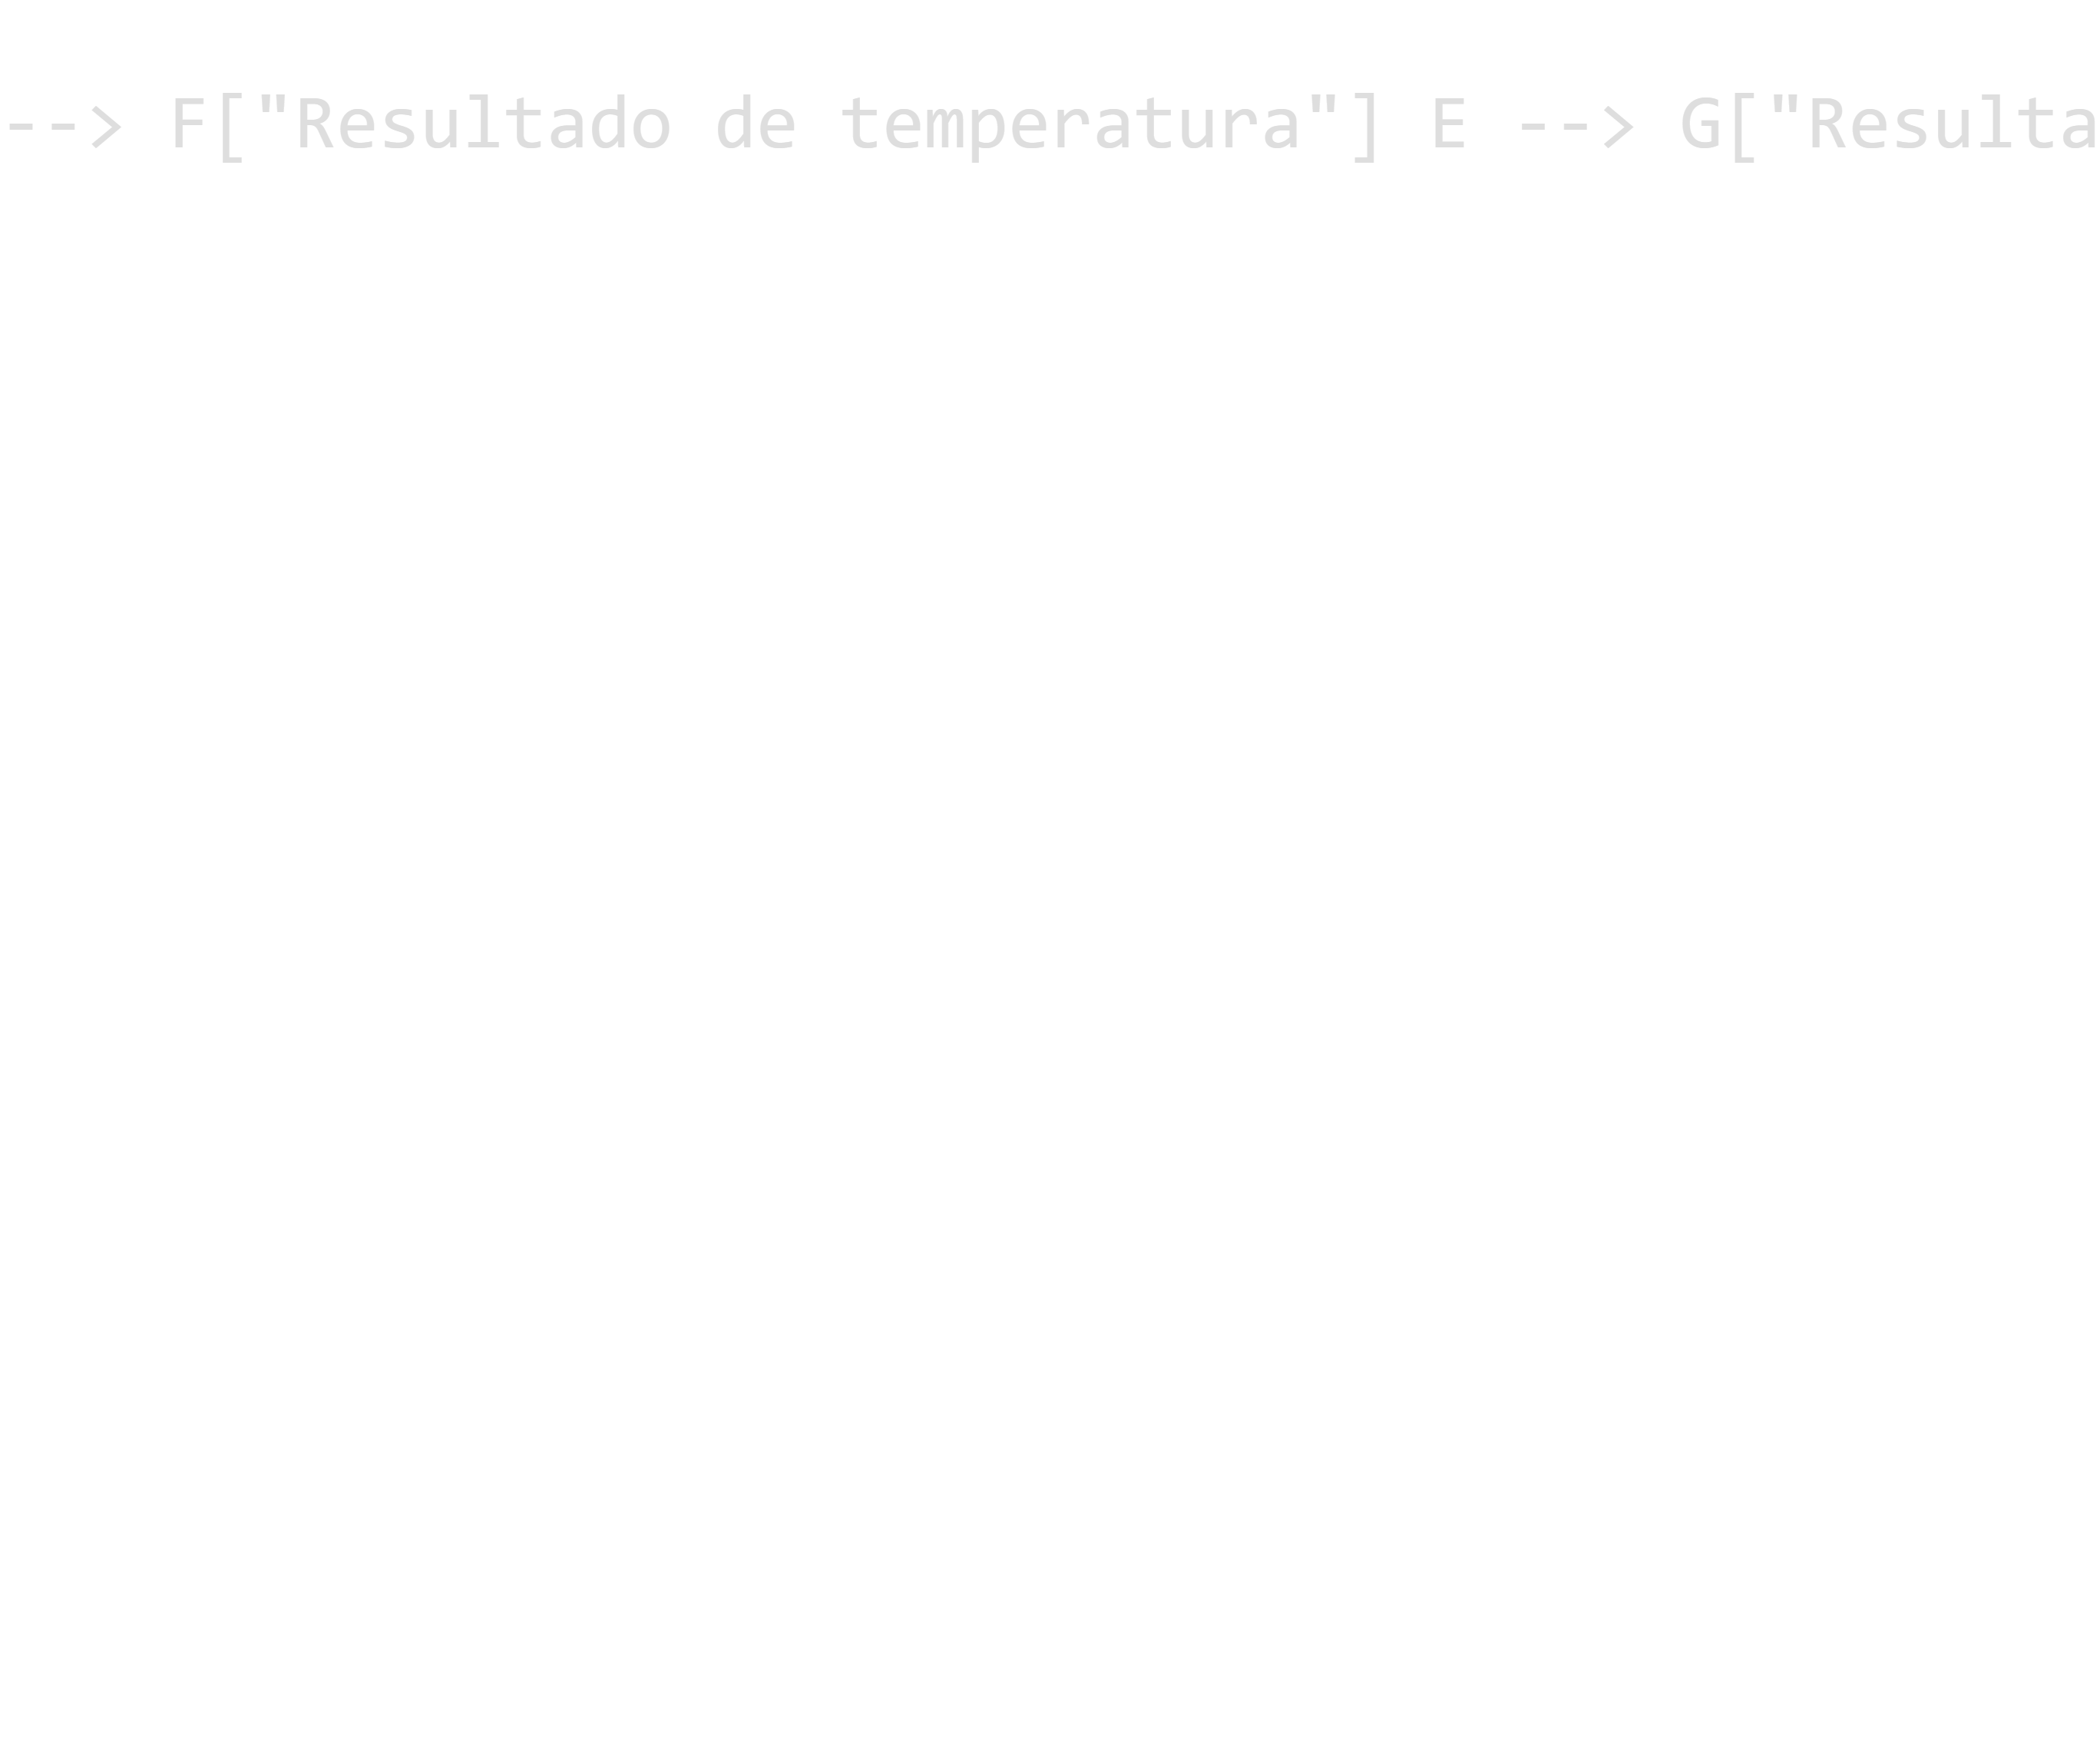
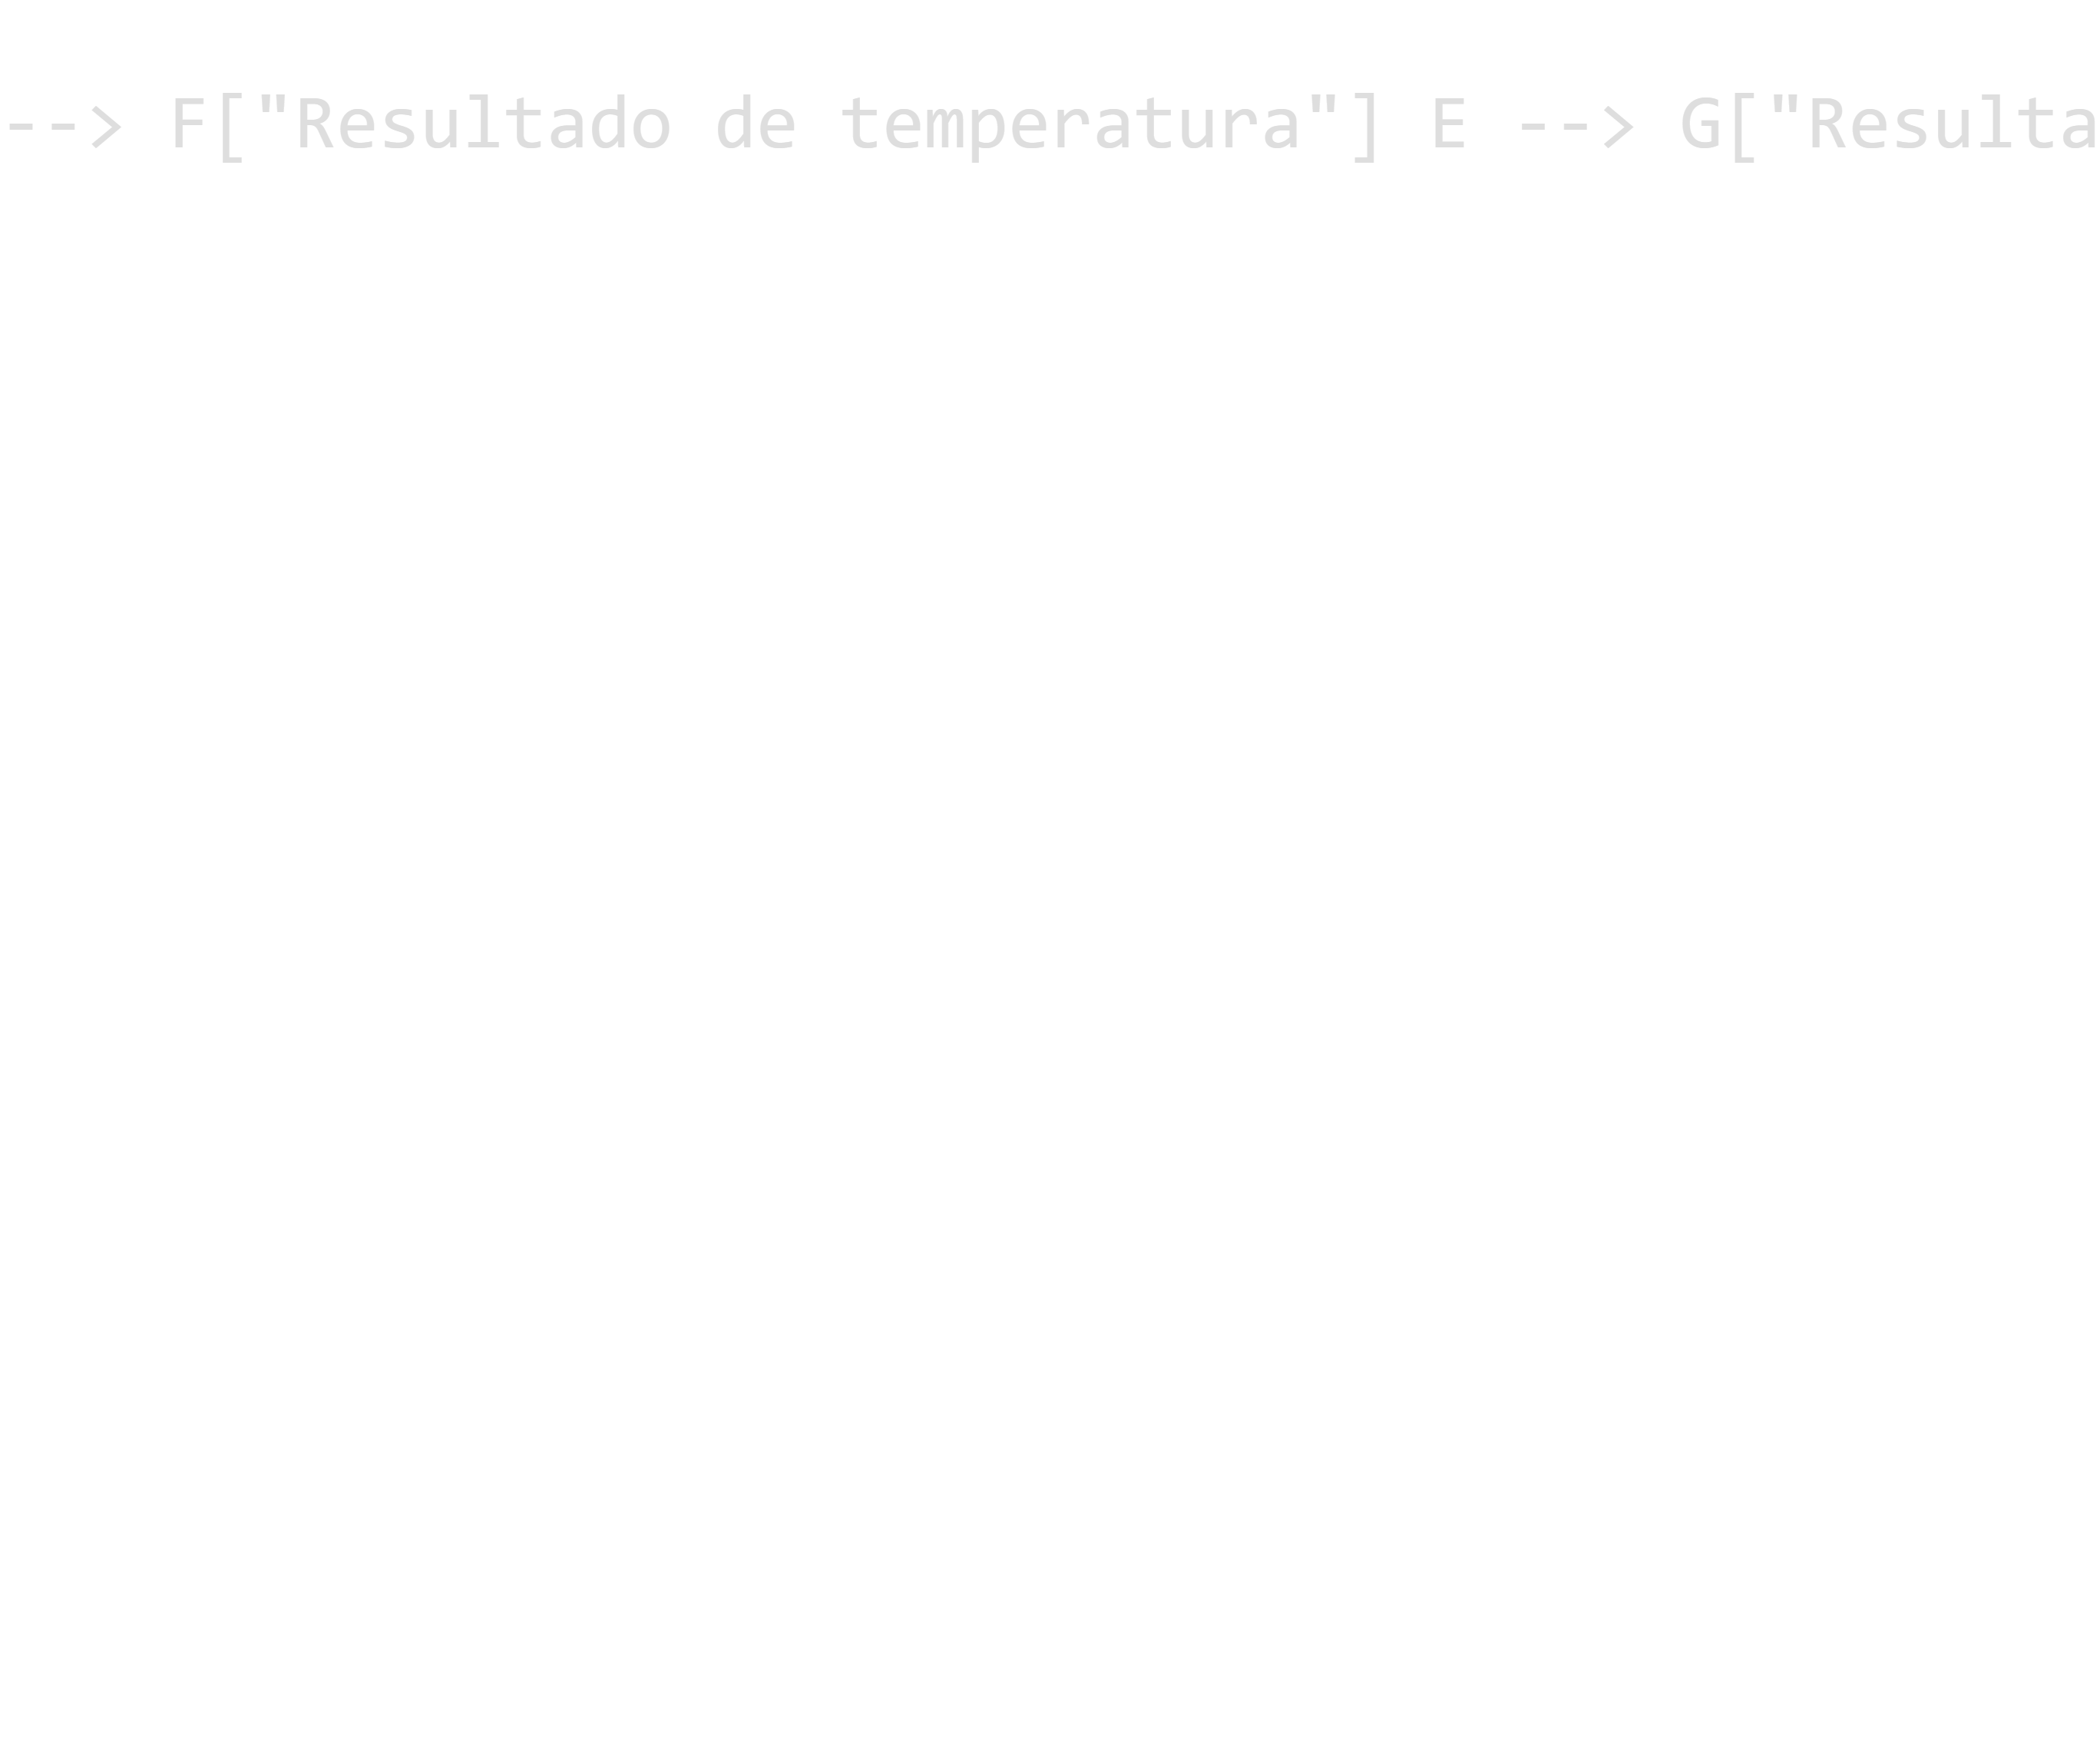

## Explicación de responsabilidades
- datos/lecturas.csv: almacena las lecturas de temperatura y humedad.
- paquetes/confort.py: contiene la lógica del proyecto.
- clasificar_temperatura(): devuelve una categoría de temperatura.
- es_humedad_adecuada(): indica si la humedad está dentro del rango recomendado.
- pruebas/test_confort.py: valida que las funciones funcionen correctamente.
- requirements.txt: permite recrear el mismo entorno de trabajo en cualquier equipo.

## Funciones

def clasificar_temperatura(temperatura: float) -> str:
- Parametro: temperatura
- Retorno: str

def es_humedad_adecuada(humedad: float) -> bool:
- Parametro: humedad
- Retorno: bool

## Pruebas previstas:
- Temperatura límite 18.
- límite 27.
- Humedad límite 30.
- Humedad fuera de rango.

## Dependencias declaradas:
- pytest

## Procedimiento para recrear el entorno
1. Crear el entorno virtual
2. Activar el entorno virtual
3. Instalar dependencias con pip install -r requirements.txt
4. Verificar que esté todo bien
5. Ejecutar python -m pytest pruebas

## Nombres locales -> Solo existen dentro de la función
- temperatura
- humedad

## Por qué no usar rutas personales
- La ruta que una persona utiliza en su ordenador no será la misma que otra persona tenga en el suyo.. Si se utilizan rutas personales, otra persona no podrá ejecutar el proyecto sin modificar el código.

## Autoevaluación

Comprueba que puedes distinguir ámbito local y global; módulo y paquete; dependencia y entorno virtual; y un import correcto de una modificación global oculta.

- [Módulos](https://docs.python.org/3/tutorial/modules.html)
- [Entornos virtuales](https://docs.python.org/3/library/venv.html)